# 01 - EDA dan Split Data (Data Engineer)
**Proyek:** Diagnosis Dini Penyakit Daun Padi | **Dataset:** [Rice Disease Dataset, Kaggle](https://www.kaggle.com/datasets/anshulm257/rice-disease-dataset)

Notebook ini menyiapkan data untuk seluruh kelompok:
1. Memeriksa dataset: jumlah gambar per kelas, resolusi, ukuran file, gambar rusak.
2. Mendeteksi duplikat persis dan gambar hampir sama (termasuk salinan yang diputar/dibalik).
3. Mengelompokkan foto beruntun dari daun yang sama (sesi pemotretan) berdasarkan waktu di nama file.
4. Mencocokkan salinan augmentasi bawaan dataset (`aug_...`) dengan foto aslinya memakai fitur CNN pretrained.
5. Membagi **foto asli** 70/15/15 per kelompok; salinan `aug_` hanya boleh masuk train, sehingga validasi dan test bersih dari kebocoran.
6. Menyimpan gambar yang sudah dikecilkan dan file `data/splits.csv`.

**Hasil untuk anggota lain:** `data/splits.csv`, folder `data/processed/rice_256/`, dan modul `src/data/data_utils.py`.

## 0. Persiapan
Notebook dijalankan dari dalam repo (folder `notebooks/`). Di Google Colab, repo di-clone otomatis ke `/content/repo`; bila `data_utils.py` belum ada di GitHub, unggah file itu ke panel Files Colab.

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/sam01149/Deeplearning_rice_disease_prediction.git"

def find_repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "src" / "data" / "data_utils.py").exists():
            return p
    return None

ROOT = find_repo_root()
if ROOT is None and "google.colab" in sys.modules:
    if not Path("/content/repo").exists():
        subprocess.run(["git", "clone", REPO_URL, "/content/repo"], check=True)
    ROOT = Path("/content/repo")
    du_path = ROOT / "src" / "data" / "data_utils.py"
    if not du_path.exists():                                  # belum di-push ke GitHub: pakai file yang diunggah ke Colab
        if not Path("/content/data_utils.py").exists():
            raise FileNotFoundError("Unggah data_utils.py ke panel Files Colab, lalu jalankan ulang sel ini.")
        du_path.parent.mkdir(parents=True, exist_ok=True)
        du_path.write_bytes(Path("/content/data_utils.py").read_bytes())
    for init in (ROOT / "src" / "__init__.py", ROOT / "src" / "data" / "__init__.py"):
        init.touch()
if ROOT is None:
    raise RuntimeError("Jalankan notebook ini dari dalam folder repo (notebooks/), atau di Google Colab.")
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
print("Folder repo:", ROOT)

try:
    import imagehash
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imagehash"], check=True)

Folder repo: c:\Users\hp\Downloads\DeepLearning\Deeplearning_rice_disease_prediction


In [2]:
import re, glob, zipfile, hashlib, random, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, UnidentifiedImageError
import imagehash
from src.data import data_utils as du
warnings.filterwarnings("ignore")

SEED           = du.SEED          # 42, sama untuk semua anggota
SPLIT_RATIO    = (0.70, 0.15, 0.15)
SESSION_GAP_S  = 5                # foto berjeda < 5 detik = foto beruntun daun yang sama (puncak histogram jeda ada di 1-3 detik)
PHASH_MAX_DIST = 6                # jarak Hamming perceptual hash: <= 6 dianggap hampir sama; cek contoh di langkah 4
MARGIN         = 0.05             # salinan aug_ dipakai hanya bila kemiripannya ke foto TRAIN terdekat > ke foto VAL/TEST terdekat + MARGIN
KEEP_MIN       = 0.65             # salinan aug_ dipakai hanya bila kemiripan ke foto train terdekat >= ini (sumber dikenali dengan yakin)
ORIG_DUP_MIN   = 0.90             # dua FOTO ASLI dengan kemiripan >= ini dianggap foto daun yang sama (digabung ke satu kelompok)
EMB_WEIGHTS    = os.environ.get("EMB_WEIGHTS", "imagenet")   # bobot pretrained EfficientNetB0 (terunduh otomatis +-16 MB)
RAW_DIR        = Path("data/raw")
PROCESSED_DIR  = du.PROCESSED_DIR
SPLITS_CSV     = du.SPLITS_CSV
FIG_DIR        = Path("reports/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
EXTS           = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
random.seed(SEED); np.random.seed(SEED)

## 1. Mengambil dataset
- **Cara A (manual):** klik **Download** di halaman Kaggle, taruh file `.zip` di `data/raw/`.
- **Cara B (Kaggle API, disarankan di Colab):** buat token di Kaggle (Settings > API > Create New Token, akan terunduh `kaggle.json`), unggah ke panel Files Colab, lalu ubah `USE_KAGGLE_API = True`. Dataset 1 GB diunduh langsung oleh server Colab.

Folder `data/raw/` tidak di-commit ke GitHub (lihat `.gitignore`).

In [3]:
USE_KAGGLE_API = False
if USE_KAGGLE_API:
    kdir = Path.home() / ".kaggle"; kdir.mkdir(exist_ok=True)
    for cand in (Path("kaggle.json"), Path("/content/kaggle.json"), ROOT.parent / "kaggle.json"):
        if cand.exists():                                    # di Colab, file yang diunggah masuk ke /content
            cand.replace(kdir / "kaggle.json"); break
    if not (kdir / "kaggle.json").exists():
        raise FileNotFoundError("kaggle.json belum diunggah. Di Colab: panel Files (ikon folder) > Upload > kaggle.json")
    (kdir / "kaggle.json").chmod(0o600)
    subprocess.run(["kaggle", "datasets", "download", "-d", "anshulm257/rice-disease-dataset", "-p", str(RAW_DIR)], check=True)

for z in RAW_DIR.glob("*.zip"):
    target = RAW_DIR / z.stem
    if not target.exists():
        print("Mengekstrak", z.name)
        with zipfile.ZipFile(z) as f:
            f.extractall(target)

def find_class_root(base):
    best, best_n = None, 0
    for root, dirs, _ in os.walk(base):
        n = sum(any(f.lower().endswith(EXTS) for f in os.listdir(os.path.join(root, d))) for d in dirs)
        if n > best_n:
            best, best_n = Path(root), n
    return best

SRC = find_class_root(RAW_DIR)
if SRC is None:
    raise FileNotFoundError("Dataset belum ada di data/raw/. Ikuti Cara A atau B, lalu jalankan ulang sel ini.")
CLASSES = sorted(d.name for d in SRC.iterdir() if d.is_dir())
print("Folder dataset:", SRC)
print("Kelas (urutan label):", CLASSES)

Folder dataset: data\raw\Rice Disease Dataset\Rice_Leaf_AUG
Kelas (urutan label): ['Bacterial Leaf Blight', 'Brown Spot', 'Healthy Rice Leaf', 'Leaf Blast', 'Leaf scald', 'Sheath Blight']


## 2. Inventaris data
Setiap gambar dibuka sekali untuk mencatat ukuran file, resolusi, dan mendeteksi gambar rusak.

In [4]:
rows = []
for c in CLASSES:
    for f in sorted(os.listdir(SRC / c)):
        if not f.lower().endswith(EXTS):
            continue
        p = SRC / c / f
        rec = {"path": str(p), "label": c, "filename": f, "kb": p.stat().st_size / 1024}
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                im = ImageOps.exif_transpose(im)
                rec["width"], rec["height"] = im.size
            rec["corrupt"] = False
        except (UnidentifiedImageError, OSError):
            rec["corrupt"] = True
        rows.append(rec)
df = pd.DataFrame(rows)
print(f"Total file gambar: {len(df):,} | rusak (dibuang): {int(df.corrupt.sum())}")
df = df[~df.corrupt].reset_index(drop=True)

summary = df.groupby("label").agg(jumlah=("path", "size"), ukuran_kb_rata2=("kb", "mean"),
                                  lebar_median=("width", "median"), tinggi_median=("height", "median")).round(0)
summary.loc["TOTAL"] = [len(df), round(df.kb.mean()), df.width.median(), df.height.median()]
summary

Total file gambar: 3,829 | rusak (dibuang): 0


,jumlah,ukuran_kb_rata2,lebar_median,tinggi_median
label,,,,
Bacterial Leaf Blight,636,173.0,224.0,224.0
Brown Spot,646,204.0,224.0,224.0
Healthy Rice Leaf,653,482.0,224.0,224.0
Leaf Blast,634,177.0,224.0,224.0
Leaf scald,628,105.0,224.0,224.0
Sheath Blight,632,487.0,224.0,224.0
TOTAL,3829,272.0,224.0,224.0


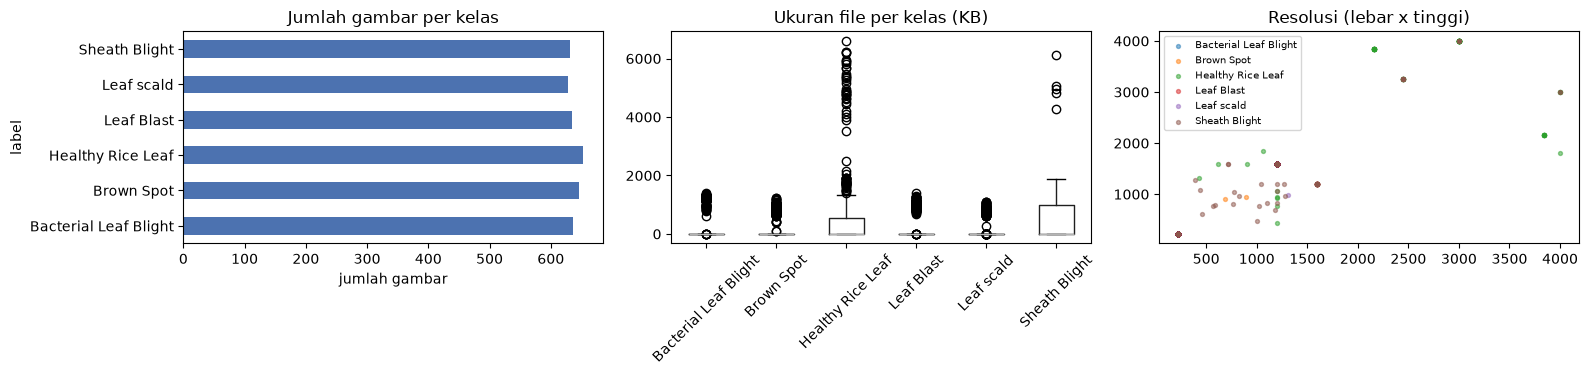

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.label.value_counts().reindex(CLASSES).plot.barh(ax=ax[0], color="#4C72B0")
ax[0].set_title("Jumlah gambar per kelas"); ax[0].set_xlabel("jumlah gambar")
df.boxplot(column="kb", by="label", ax=ax[1], rot=45, grid=False)
ax[1].set_title("Ukuran file per kelas (KB)"); ax[1].set_xlabel(""); plt.suptitle("")
for lab in CLASSES:
    s = df[df.label == lab]
    ax[2].scatter(s.width, s.height, s=8, alpha=0.5, label=lab)
ax[2].set_title("Resolusi (lebar x tinggi)"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_distribusi.png", dpi=150); plt.show()

**Cek shortcut learning:** bila ukuran file atau resolusi sangat berbeda antar kelas (misalnya satu kelas difoto dengan kamera lain),
model bisa belajar mengenali "jenis foto", bukan penyakitnya. Catat temuan ini untuk evaluator (cek dengan Grad-CAM) dan bagian keterbatasan laporan.

## 3. Contoh gambar tiap kelas

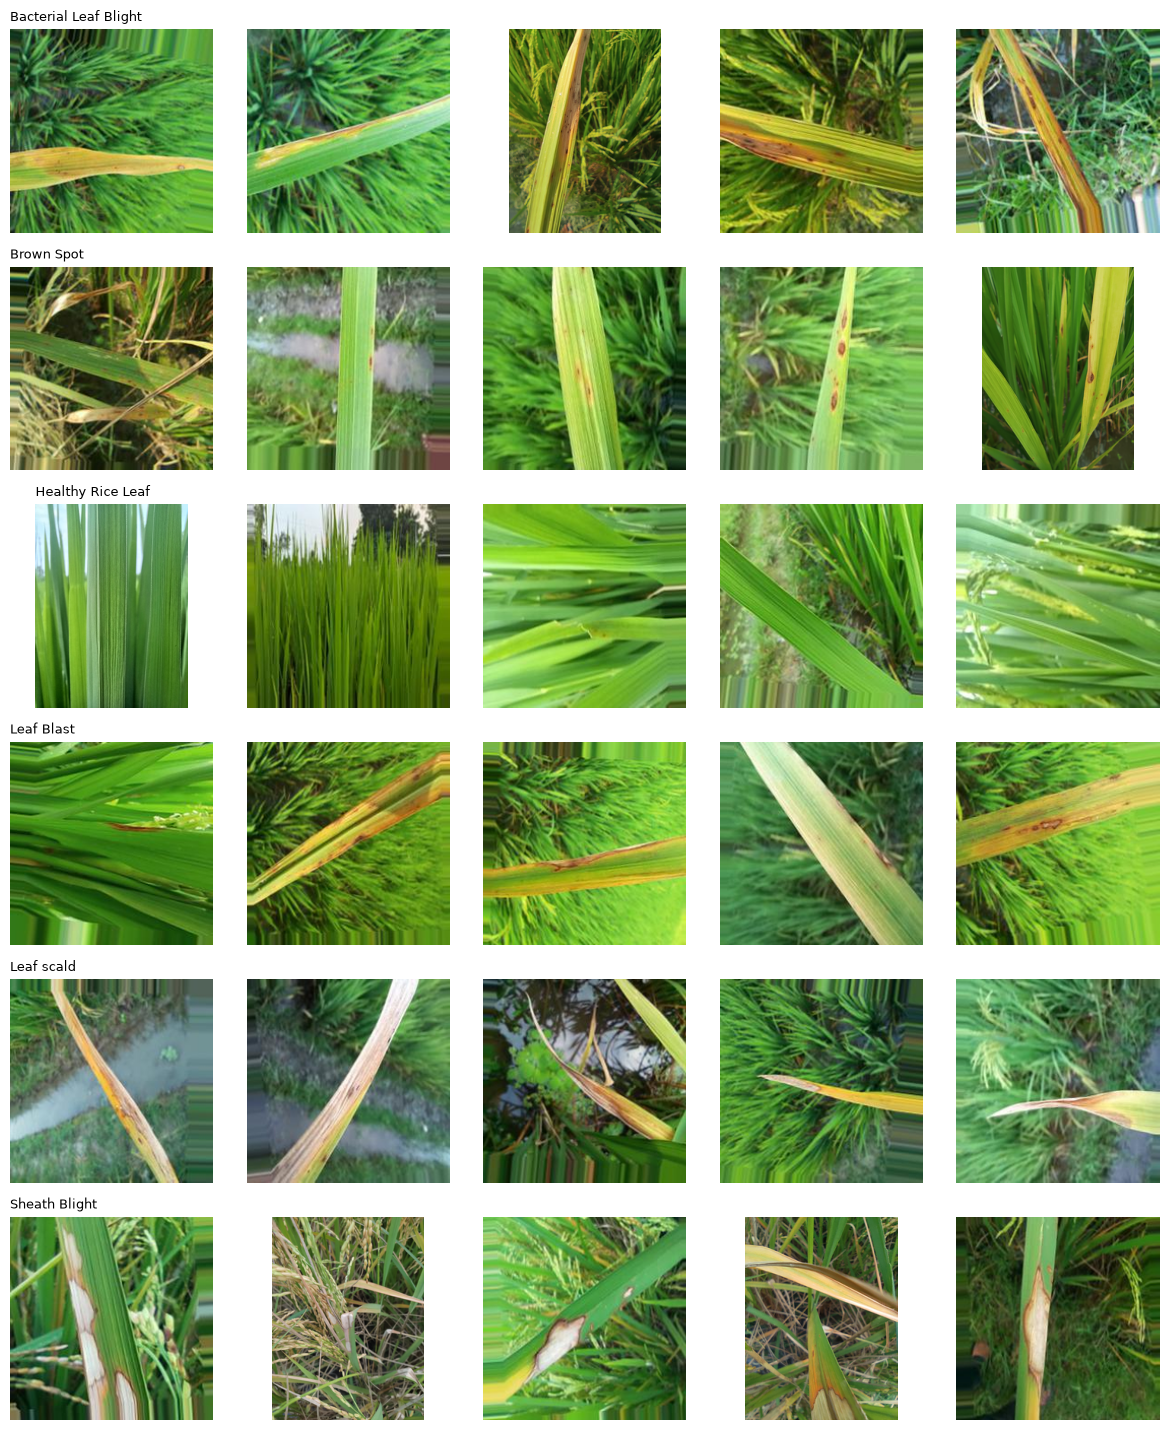

In [6]:
n_show = 5
fig, axes = plt.subplots(len(CLASSES), n_show, figsize=(n_show * 2.4, len(CLASSES) * 2.4))
for r, lab in enumerate(CLASSES):
    sample = df[df.label == lab].sample(n=min(n_show, (df.label == lab).sum()), random_state=SEED)
    for c in range(n_show):
        a = axes[r, c]; a.axis("off")
        if c < len(sample):
            with Image.open(sample.path.iloc[c]) as im:
                a.imshow(du.shrink_pil(im, 200))
        if c == 0:
            a.set_title(lab, fontsize=9, loc="left")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_contoh_gambar.png", dpi=150); plt.show()

## 4. Duplikat dan gambar hampir sama
- **Duplikat persis:** isi file identik (hash MD5 sama).
- **Hampir sama:** perceptual hash dihitung untuk 8 orientasi (4 rotasi x dibalik/tidak), lalu diambil jarak terkecil.
  Jadi salinan yang diputar 90 derajat atau dibalik tetap terdeteksi.

Keduanya berbahaya bila satu masuk train dan satunya masuk test (kebocoran data).

In [7]:
def md5(p):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

df["md5"] = df.path.map(md5)
print(f"Duplikat persis: {int(df.duplicated('md5').sum())} file berlebih")

def phash8(p):
    """Perceptual hash untuk 8 orientasi gambar, masing-masing sebagai bilangan 64-bit."""
    with Image.open(p) as im:
        im = du.shrink_pil(im, 256)
    out = []
    for flip in (False, True):
        base = ImageOps.mirror(im) if flip else im
        for k in range(4):
            out.append(int(str(imagehash.phash(base.rotate(90 * k, expand=True))), 16))
    return out

H8 = np.array([phash8(p) for p in df.path], dtype=np.uint64)    # n x 8
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def min_dist(a, B):
    """Jarak Hamming terkecil antara hash a (k gambar, orientasi asli) dan semua orientasi gambar B."""
    x = (a[:, None, None] ^ B[None, :, :]).view(np.uint8).reshape(len(a), B.shape[0], B.shape[1], 8)
    return POP[x].sum(-1, dtype=np.int16).min(-1)

pairs, dist_all, CHUNK = [], [], 64
for s0 in range(0, len(H8), CHUNK):
    d = min_dist(H8[s0:s0 + CHUNK, 0], H8)
    ii, jj = np.nonzero(d <= PHASH_MAX_DIST + 4)                 # simpan juga yang "hampir" untuk dicek manual
    ii = ii + s0
    keep = jj > ii
    pairs.append(np.stack([ii[keep], jj[keep], d[ii[keep] - s0, jj[keep]]], 1))
cand = np.concatenate(pairs)
near_pairs = cand[cand[:, 2] <= PHASH_MAX_DIST][:, :2]
cross = sum(df.label[i] != df.label[j] for i, j in near_pairs)
print(f"Pasangan hampir sama (jarak <= {PHASH_MAX_DIST}): {len(near_pairs)} | beda kelas: {cross}")
if cross:
    print("PERHATIAN: ada gambar hampir sama dengan label berbeda -> kemungkinan salah label, cek manual.")

Duplikat persis: 31 file berlebih
Pasangan hampir sama (jarak <= 6): 266 | beda kelas: 2
PERHATIAN: ada gambar hampir sama dengan label berbeda -> kemungkinan salah label, cek manual.


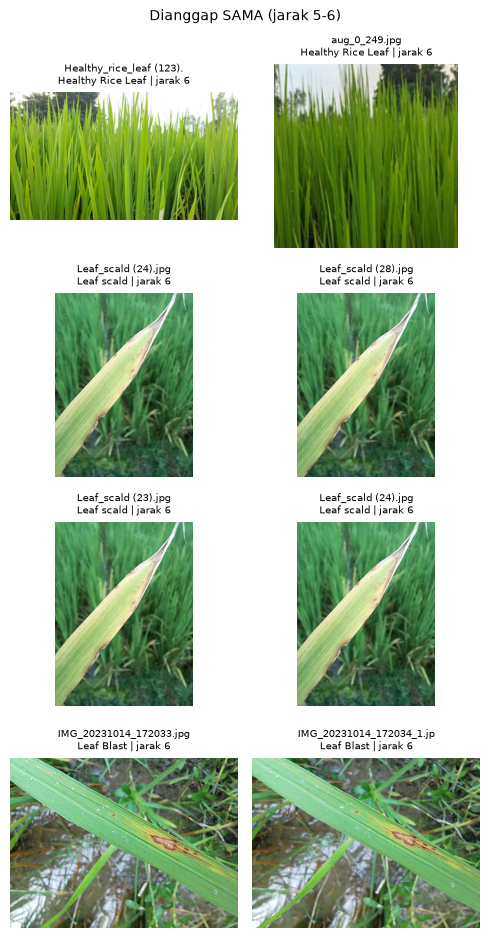

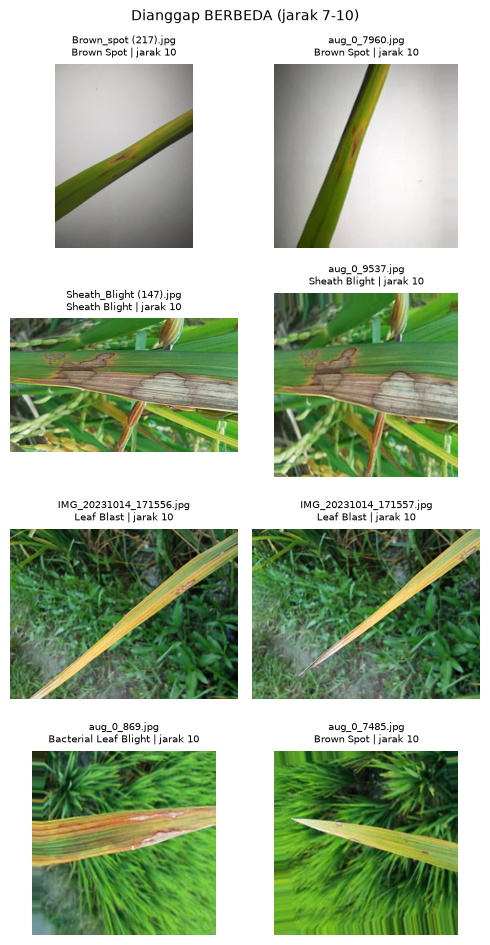

Bila pasangan 'BERBEDA' ternyata daun yang sama, naikkan PHASH_MAX_DIST; bila pasangan 'SAMA' ternyata beda daun, turunkan.


In [8]:
# cek ambang secara visual: contoh pasangan TEPAT di bawah dan di atas ambang
def show_pairs(sel, title, fname, n=4):
    sel = sel[:n]
    if len(sel) == 0:
        print("Tidak ada pasangan untuk:", title); return
    fig, axes = plt.subplots(len(sel), 2, figsize=(5, 2.4 * len(sel)), squeeze=False)
    for r, (i, j, dd) in enumerate(sel):
        for c, k in enumerate((i, j)):
            with Image.open(df.path[k]) as im:
                axes[r, c].imshow(du.shrink_pil(im, 200))
            axes[r, c].set_title(f"{df.filename[k][:24]}\n{df.label[k]} | jarak {dd}", fontsize=7); axes[r, c].axis("off")
    plt.suptitle(title, fontsize=10); plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=150); plt.show()

rng = np.random.RandomState(SEED)
below = cand[(cand[:, 2] > PHASH_MAX_DIST - 2) & (cand[:, 2] <= PHASH_MAX_DIST)]
above = cand[cand[:, 2] > PHASH_MAX_DIST]
show_pairs(below[rng.permutation(len(below))], f"Dianggap SAMA (jarak {PHASH_MAX_DIST-1}-{PHASH_MAX_DIST})", "cek_ambang_sama.png")
show_pairs(above[rng.permutation(len(above))], f"Dianggap BERBEDA (jarak {PHASH_MAX_DIST+1}-{PHASH_MAX_DIST+4})", "cek_ambang_beda.png")
print("Bila pasangan 'BERBEDA' ternyata daun yang sama, naikkan PHASH_MAX_DIST; bila pasangan 'SAMA' ternyata beda daun, turunkan.")

## 5. Pengelompokan per sesi pemotretan
Nama file foto HP memuat waktu, misalnya `IMG_20231014_172829.jpg` = 14 Okt 2023 pukul 17:28:29.
Foto dalam satu kelas yang berjeda kurang dari `SESSION_GAP_S` detik dianggap satu sesi.
Duplikat persis dan gambar hampir sama juga digabung ke kelompok yang sama. File tanpa waktu menjadi kelompok sendiri,
kecuali hampir sama dengan file lain.

File dengan waktu di nama file: 395 dari 3,829


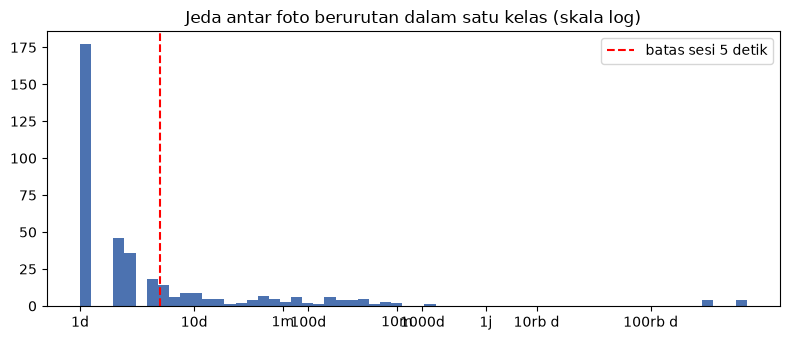

Pilih SESSION_GAP_S di 'lembah' histogram: kiri = foto beruntun (daun sama), kanan = pindah daun/lokasi.


In [9]:
TS_RE = re.compile(r"(20\d{6})[_-]?(\d{6})")
def parse_ts(name):
    m = TS_RE.search(name)
    try:
        return datetime.strptime(m.group(1) + m.group(2), "%Y%m%d%H%M%S") if m else pd.NaT
    except ValueError:
        return pd.NaT

df["timestamp"] = df.filename.map(parse_ts)
print(f"File dengan waktu di nama file: {int(df.timestamp.notna().sum()):,} dari {len(df):,}")

gaps = (df[df.timestamp.notna()].sort_values(["label", "timestamp"])
          .groupby("label").timestamp.diff().dt.total_seconds().dropna())
if len(gaps):
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.hist(np.log10(gaps.clip(lower=1)), bins=60, color="#4C72B0")
    ax.axvline(np.log10(SESSION_GAP_S), color="red", ls="--", label=f"batas sesi {SESSION_GAP_S} detik")
    ax.set_xticks([0, 1, np.log10(60), 2, np.log10(600), 3, np.log10(3600), 4, 5])
    ax.set_xticklabels(["1d", "10d", "1m", "100d", "10m", "1000d", "1j", "10rb d", "100rb d"])
    ax.set_title("Jeda antar foto berurutan dalam satu kelas (skala log)"); ax.legend()
    plt.tight_layout(); plt.savefig(FIG_DIR / "jeda_antar_foto.png", dpi=150); plt.show()
    print("Pilih SESSION_GAP_S di 'lembah' histogram: kiri = foto beruntun (daun sama), kanan = pindah daun/lokasi.")

In [10]:
parent = list(range(len(df)))
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb: parent[rb] = ra

for lab, sub in df[df.timestamp.notna()].groupby("label"):
    sub = sub.sort_values("timestamp"); idx, ts = sub.index.to_list(), sub.timestamp.to_list()
    for k in range(1, len(idx)):
        if (ts[k] - ts[k - 1]).total_seconds() < SESSION_GAP_S:
            union(idx[k - 1], idx[k])
for _, g in df.groupby("md5"):
    for k in g.index[1:]: union(g.index[0], k)
for i, j in near_pairs:
    union(int(i), int(j))
df["group"] = [find(i) for i in range(len(df))]

gsize = df.groupby("group").size()
per_class = df.groupby("label").size()
largest = df.groupby(["label", "group"]).size().groupby("label").max()
check = pd.DataFrame({"gambar": per_class, "jumlah_sesi": df.groupby("label").group.nunique(),
                      "sesi_terbesar": largest, "porsi_sesi_terbesar_%": (largest / per_class * 100).round(1)})
print(f"Jumlah kelompok: {len(gsize):,} | rata-rata {gsize.mean():.1f} gambar per kelompok")
if (check["porsi_sesi_terbesar_%"] > 15).any():
    print("PERHATIAN: ada sesi > 15% dari kelasnya. Split per kelas akan sulit seimbang; turunkan SESSION_GAP_S atau PHASH_MAX_DIST.")
mixed = int((df.groupby("group").label.nunique() > 1).sum())
print("Kelompok berisi lebih dari satu kelas:", mixed, "(harus 0; bila tidak, cek manual kemungkinan salah label)")
check

Jumlah kelompok: 3,434 | rata-rata 1.1 gambar per kelompok
Kelompok berisi lebih dari satu kelas: 2 (harus 0; bila tidak, cek manual kemungkinan salah label)


,gambar,jumlah_sesi,sesi_terbesar,porsi_sesi_terbesar_%
label,,,,
Bacterial Leaf Blight,636,566,11,1.7
Brown Spot,646,594,13,2.0
Healthy Rice Leaf,653,627,6,0.9
Leaf Blast,634,548,16,2.5
Leaf scald,628,595,14,2.2
Sheath Blight,632,506,10,1.6


## 5b. Salinan augmentasi bawaan dataset (`aug_...`)
Sebagian besar gambar di dataset ini adalah **salinan augmentasi** buatan pengunggah (diputar dengan sudut bebas, di-zoom, digeser) dari foto asli.
Perceptual hash tidak cukup untuk menemukannya, jadi dipakai **fitur EfficientNetB0 pretrained** (vektor 1.280 angka per gambar) dan
kemiripan cosine. Foto asli dihitung dalam 8 orientasi agar salinan yang diputar tetap cocok.

Aturan yang dipakai:
- **Split dilakukan hanya pada foto asli.** Foto asli yang sangat mirip (kemiripan >= `ORIG_DUP_MIN`, kelas sama) digabung ke kelompok yang sama.
- **Salinan `aug_` hanya boleh masuk train.** Setiap salinan dibandingkan dengan foto asli terdekat di train dan foto asli terdekat
  di validasi/test (kelas sama). Salinan dipakai hanya bila **jelas lebih mirip ke foto train** (selisih > `MARGIN`); selain itu dibuang.
  Aturan ini tidak memerlukan ambang mutlak, karena salinan bawaan dataset diubah cukup berat (rotasi bebas, zoom, geser).

is_aug,foto asli,salinan aug_,Total
label,,,
Bacterial Leaf Blight,89,547,636
Brown Spot,150,496,646
Healthy Rice Leaf,187,466,653
Leaf Blast,108,526,634
Leaf scald,76,552,628
Sheath Blight,288,344,632
Total,898,2931,3829


fitur foto asli: 0/898
fitur foto asli: 320/898
fitur foto asli: 640/898
Fitur selesai: 898 foto asli (x8 orientasi), 2,931 salinan aug_
Pasangan foto asli sangat mirip (>= 0.9): kelas sama 354 (digabung) | beda kelas 0 (hanya dilaporkan)


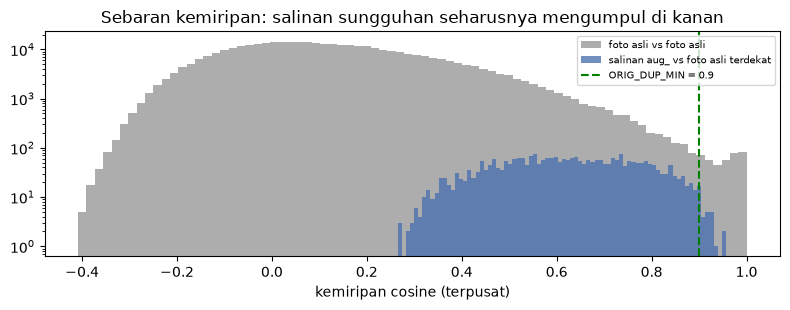

In [11]:
from tensorflow import keras
df["is_aug"] = df.filename.str.lower().str.startswith("aug_")
display(pd.crosstab(df.label, df.is_aug.map({False: "foto asli", True: "salinan aug_"}), margins=True, margins_name="Total"))

backbone = keras.applications.EfficientNetB0(include_top=False, weights=EMB_WEIGHTS, pooling="avg", input_shape=(224, 224, 3))

def load224(p):
    with Image.open(p) as im:
        return np.asarray(du.shrink_pil(im, 224).resize((224, 224)), dtype=np.float32)

def dihedral(x):
    """8 orientasi: 4 rotasi x (asli, dibalik)."""
    return [np.rot90(v, k) for v in (x, x[:, ::-1]) for k in range(4)]

def embed(batch):
    return backbone.predict(np.stack(batch), batch_size=64, verbose=0)

def center_norm(E, mu):
    """Kurangi rata-rata lalu normalkan: gambar tak berhubungan mendekati 0, salinan sungguhan mendekati 1."""
    E = E - mu
    return E / np.clip(np.linalg.norm(E, axis=-1, keepdims=True), 1e-8, None)

orig_idx = df.index[~df.is_aug].to_numpy(); aug_idx = df.index[df.is_aug].to_numpy()
E_orig = []
for s0 in range(0, len(orig_idx), 16):
    imgs = [load224(df.path[i]) for i in orig_idx[s0:s0 + 16]]
    E_orig.append(embed([v for x in imgs for v in dihedral(x)]).reshape(len(imgs), 8, -1))
    if s0 % 320 == 0: print(f"fitur foto asli: {s0:,}/{len(orig_idx):,}")
E_orig = np.concatenate(E_orig)                                    # n_asli x 8 x 1280
E_aug = (np.concatenate([embed([load224(df.path[i]) for i in aug_idx[s0:s0 + 64]]) for s0 in range(0, len(aug_idx), 64)])
         if len(aug_idx) else np.zeros((0, E_orig.shape[-1]), dtype=np.float32))
mu = np.concatenate([E_orig.reshape(-1, E_orig.shape[-1]), E_aug]).mean(0)
E_orig, E_aug = center_norm(E_orig, mu), center_norm(E_aug, mu)
D = E_orig.shape[-1]
S_aug = (E_aug @ E_orig.reshape(-1, D).T).reshape(len(aug_idx), len(orig_idx), 8).max(-1)          # salinan x foto asli
S_oo = (E_orig[:, 0, :] @ E_orig.reshape(-1, D).T).reshape(len(orig_idx), len(orig_idx), 8).max(-1)  # foto asli x foto asli
np.fill_diagonal(S_oo, -1)
print(f"Fitur selesai: {len(orig_idx):,} foto asli (x8 orientasi), {len(aug_idx):,} salinan aug_")

# gabungkan foto asli yang sangat mirip (kelas sama) ke kelompok yang sama
lab_o = df.label[orig_idx].to_numpy()
ii, jj = np.nonzero(np.triu(S_oo >= ORIG_DUP_MIN, 1))
same = lab_o[ii] == lab_o[jj]
print(f"Pasangan foto asli sangat mirip (>= {ORIG_DUP_MIN}): kelas sama {int(same.sum())} (digabung) | beda kelas {int((~same).sum())} (hanya dilaporkan)")
parent_backup = parent.copy()
for i, j in zip(ii[same], jj[same]):
    union(int(orig_idx[i]), int(orig_idx[j]))
groups_try = pd.Series([find(i) for i in range(len(df))], index=df.index)
biggest = (groups_try[~df.is_aug].value_counts().max() / (~df.is_aug).sum()) if (~df.is_aug).any() else 0
if biggest > 0.05:      # pengaman efek berantai: satu kelompok > 5% foto asli berarti ambang terlalu longgar
    parent[:] = parent_backup
    print(f"PERHATIAN: penggabungan membuat kelompok berisi {biggest:.0%} foto asli -> DIBATALKAN. Naikkan ORIG_DUP_MIN.")
df["group"] = [find(i) for i in range(len(df))]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(S_oo[np.triu_indices(len(orig_idx), 1)], bins=80, color="#999999", alpha=0.8, label="foto asli vs foto asli")
best = S_aug.max(1) if len(aug_idx) else []
ax.hist(best, bins=80, color="#4C72B0", alpha=0.8, label="salinan aug_ vs foto asli terdekat")
for v, c, n in [(ORIG_DUP_MIN, "green", "ORIG_DUP_MIN")]:
    ax.axvline(v, color=c, ls="--", label=f"{n} = {v}")
ax.set_yscale("log"); ax.set_xlabel("kemiripan cosine (terpusat)"); ax.legend(fontsize=7)
ax.set_title("Sebaran kemiripan: salinan sungguhan seharusnya mengumpul di kanan")
plt.tight_layout(); plt.savefig(FIG_DIR / "kemiripan_cnn.png", dpi=150); plt.show()

Pasangan foto berurutan: 865 | digabung (>= 0.65): 167 | dilewati karena batas 8 foto: 23
Kelompok foto asli: 347 | terbesar 16 foto | rata-rata 2.59 foto per kelompok


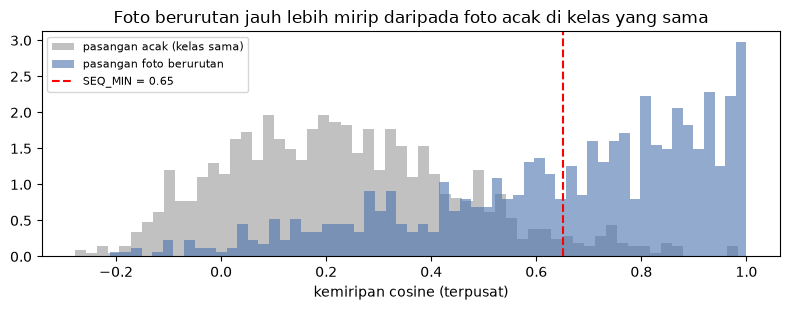

In [12]:
# 5c) Foto asli berurutan dari daun yang sama: (n) dan (n+1), atau foto HP berjeda < 5 menit
SEQ_MIN       = 0.65   # dua foto asli BERURUTAN digabung bila kemiripan CNN >= ini
SEQ_MAX_GROUP = 8      # batas ukuran kelompok hasil penggabungan (foto asli), mencegah efek berantai
pos = {ix: k for k, ix in enumerate(orig_idx)}

def seq_key(f):
    m = re.search(r"\((\d+)\)", f)
    if m:
        return ("nomor", int(m.group(1)))
    ts = parse_ts(f)
    return None if pd.isna(ts) else ("waktu", ts.timestamp())

o = df.loc[orig_idx, ["label", "filename"]].copy()
o["key"] = o.filename.map(seq_key)
o = o[o.key.notna()]
o["jenis"], o["urut"] = o.key.str[0], o.key.str[1]

pairs_seq = []
for (lab, jenis), sub in o.groupby(["label", "jenis"]):
    sub = sub.sort_values("urut"); idx, ur = sub.index.to_list(), sub.urut.to_list()
    for k in range(1, len(idx)):
        dekat = (ur[k] - ur[k - 1] == 1) if jenis == "nomor" else (ur[k] - ur[k - 1] <= 300)
        if dekat:
            pairs_seq.append((idx[k - 1], idx[k], float(S_oo[pos[idx[k - 1]], pos[idx[k]]])))

# ukuran kelompok (jumlah foto asli) untuk membatasi penggabungan
is_orig = (~df.is_aug).to_numpy()
size = {}
for i in range(len(df)):
    r = find(i); size[r] = size.get(r, 0) + int(is_orig[i])
linked = skipped = 0
for a, b, sim in sorted(pairs_seq, key=lambda x: -x[2]):          # pasangan paling mirip digabung lebih dulu
    if sim < SEQ_MIN:
        continue
    ra, rb = find(a), find(b)
    if ra == rb:
        continue
    if size[ra] + size[rb] > SEQ_MAX_GROUP:
        skipped += 1; continue
    parent[rb] = ra; size[ra] += size[rb]; linked += 1
df["group"] = [find(i) for i in range(len(df))]
og = df[~df.is_aug].groupby("group").size()
print(f"Pasangan foto berurutan: {len(pairs_seq)} | digabung (>= {SEQ_MIN}): {linked} | dilewati karena batas {SEQ_MAX_GROUP} foto: {skipped}")
print(f"Kelompok foto asli: {len(og)} | terbesar {og.max()} foto | rata-rata {og.mean():.2f} foto per kelompok")

# perbandingan: pasangan berurutan vs pasangan acak (kelas sama)
rng = np.random.RandomState(SEED); lab_arr = df.label[orig_idx].to_numpy(); rand_sims = []
for _ in range(5000):
    i, j = rng.randint(len(orig_idx), size=2)
    if i != j and lab_arr[i] == lab_arr[j]:
        rand_sims.append(S_oo[i, j])
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(rand_sims, bins=60, alpha=0.6, density=True, color="#999999", label="pasangan acak (kelas sama)")
ax.hist([p[2] for p in pairs_seq], bins=60, alpha=0.6, density=True, color="#4C72B0", label="pasangan foto berurutan")
ax.axvline(SEQ_MIN, color="red", ls="--", label=f"SEQ_MIN = {SEQ_MIN}")
ax.set_xlabel("kemiripan cosine (terpusat)"); ax.legend(fontsize=8)
ax.set_title("Foto berurutan jauh lebih mirip daripada foto acak di kelas yang sama")
plt.tight_layout(); plt.savefig(FIG_DIR / "kemiripan_berurutan.png", dpi=150); plt.show()w

## 6. Split train / validasi / test
1. Kelompok berisi lebih dari satu kelas (gambar sama di dua folder penyakit) **dibuang** karena labelnya bertentangan.
2. **Foto asli** dibagi 70/15/15 per kelompok dan per kelas.
3. Setiap salinan `aug_`: bila satu kelompok (hash/sesi) dengan foto asli, ikut split foto itu; selain itu dibandingkan dengan foto asli
   terdekat di train dan di validasi/test. Hanya salinan yang jelas lebih mirip ke foto train yang dipakai (di train); sisanya dibuang.

In [13]:
df["status"], df["alasan"], df["split"] = "dipakai", "", None

# 1) buang kelompok lintas kelas
nlab = df.groupby("group").label.nunique()
mixed_ids = nlab[nlab > 1].index
df.loc[df.group.isin(mixed_ids), ["status", "alasan"]] = ["dibuang", "label ganda (gambar sama di dua kelas)"]
print(f"Kelompok lintas kelas dibuang: {len(mixed_ids)} kelompok, {int(df.group.isin(mixed_ids).sum())} gambar")

# 2) split foto asli per kelompok
def group_split(data, ratios=SPLIT_RATIO, seed=SEED):
    rng = np.random.RandomState(seed)
    sizes_all = data.groupby("group").size()
    main_label = data.groupby("group").label.agg(lambda s: s.value_counts().index[0])
    group_of = data.group.to_numpy()
    out = pd.Series(index=data.index, dtype=object)
    for lab in sorted(main_label.unique()):
        groups = main_label[main_label == lab].index.to_numpy().copy(); rng.shuffle(groups)
        target = dict(zip(["train", "val", "test"], np.array(ratios) * sizes_all[groups].sum()))
        count = {k: 0 for k in target}
        for g in groups:
            name = max(target, key=lambda k: target[k] - count[k])
            out[data.index[group_of == g]] = name
            count[name] += sizes_all[g]
    return out

orig_ok = df[(~df.is_aug) & (df.status == "dipakai")]
df.loc[orig_ok.index, "split"] = group_split(orig_ok)

# 3) salinan aug_: hanya boleh di train
o_ok = (df.status[orig_idx] == "dipakai").to_numpy()
o_split = df.split[orig_idx].to_numpy()
o_lab = df.label[orig_idx].to_numpy()
grp_split = df.loc[orig_ok.index].groupby("group").split.first()
df["sim_train"], df["sim_holdout"], df["sumber"], df["sumber_holdout"] = np.nan, np.nan, "", ""
for a, ix in enumerate(aug_idx):
    if df.status[ix] != "dipakai":
        continue
    same = o_ok & (o_lab == df.label[ix])
    s_tr = np.where(same & (o_split == "train"), S_aug[a], -9)
    s_ho = np.where(same & (o_split != "train"), S_aug[a], -9)
    kt, kh = int(s_tr.argmax()), int(s_ho.argmax())
    df.loc[ix, ["sim_train", "sim_holdout"]] = [float(s_tr[kt]), float(s_ho[kh])]
    df.loc[ix, ["sumber", "sumber_holdout"]] = [df.filename[orig_idx[kt]], df.filename[orig_idx[kh]]]
    g = df.group[ix]
    if g in grp_split.index:                                   # satu kelompok hash/sesi dengan foto asli
        if grp_split[g] == "train":
            df.loc[ix, ["split", "alasan"]] = ["train", "satu kelompok (hash/sesi) dengan foto train"]
        else:
            df.loc[ix, ["status", "alasan"]] = ["dibuang", f"satu kelompok dengan foto {grp_split[g]}"]
    elif max(s_tr[kt], s_ho[kh]) < KEEP_MIN:
        df.loc[ix, ["status", "alasan"]] = ["dibuang", "sumber tidak dikenali (kemiripan < KEEP_MIN)"]
    elif s_tr[kt] > s_ho[kh] + MARGIN:
        df.loc[ix, ["split", "alasan"]] = ["train", "jelas lebih mirip foto train"]
        df.loc[ix, "group"] = df.group[orig_idx[kt]]
    elif s_ho[kh] > s_tr[kt] + MARGIN:
        df.loc[ix, ["status", "alasan"]] = ["dibuang", "lebih mirip foto validasi/test"]
        df.loc[ix, "group"] = df.group[orig_idx[kh]]
    else:
        df.loc[ix, ["status", "alasan"]] = ["dibuang", "ragu-ragu (selisih <= MARGIN)"]

display(df[df.is_aug].groupby(["status", "alasan"]).size().rename("jumlah salinan aug_").to_frame())
df[["filename", "label", "is_aug", "status", "alasan", "split", "sumber", "sim_train", "sumber_holdout", "sim_holdout"]].to_csv("reports/aug_matching.csv", index=False)

# 4) pemeriksaan kebocoran
df_all = df.copy()
df = df[df.status == "dipakai"].copy()
used = set(df.index)
aug_outside_train = int((df.is_aug & (df.split != "train")).sum())
leak_groups = int((df.groupby("group").split.nunique() > 1).sum())
leak_pairs = int(sum(df_all.split[i] != df_all.split[j] for i, j in near_pairs if i in used and j in used))
tr_o = np.isin(orig_idx, df.index[(~df.is_aug) & (df.split == "train")])
ho_o = np.isin(orig_idx, df.index[(~df.is_aug) & (df.split != "train")])
leak_cnn = int((S_oo[np.ix_(tr_o, ho_o)] >= ORIG_DUP_MIN).sum())
print(f"Salinan aug_ di luar train: {aug_outside_train} | kelompok terpecah: {leak_groups} | pasangan hash lintas split: {leak_pairs}")
print(f"Pasangan foto asli train vs val/test dengan kemiripan CNN >= {ORIG_DUP_MIN} (beda kelas, hanya info): {leak_cnn}")
assert aug_outside_train == 0 and leak_groups == 0 and leak_pairs == 0, "Masih ada kebocoran data!"
per_split = pd.crosstab(df.label, df.split).reindex(columns=["train", "val", "test"], fill_value=0)
assert (per_split > 0).all().all(), f"Ada kelas tanpa data di salah satu split:\n{per_split}"

Kelompok lintas kelas dibuang: 2 kelompok, 6 gambar


jumlah salinan aug_
status  alasan                                                           
dibuang label ganda (gambar sama di dua kelas)                          5
        lebih mirip foto validasi/test                                329
        ragu-ragu (selisih <= MARGIN)                                  80
        satu kelompok dengan foto test                                 10
        satu kelompok dengan foto val                                   4
        sumber tidak dikenali (kemiripan < KEEP_MIN)                 1735
dipakai jelas lebih mirip foto train                                  741
        satu kelompok (hash/sesi) dengan foto train                    27

Salinan aug_ di luar train: 0 | kelompok terpecah: 0 | pasangan hash lintas split: 0
Pasangan foto asli train vs val/test dengan kemiripan CNN >= 0.9 (beda kelas, hanya info): 0


### Cek pencocokan secara visual
Setiap baris: salinan `aug_` (kiri), foto asli **train** terdekat (tengah), foto asli **validasi/test** terdekat (kanan).
- Baris **"dipakai, selisih tipis"**: sumber yang benar (daun yang sama) harus di **tengah**. Bila ternyata di kanan, naikkan `MARGIN`.
- Baris **"dibuang"** hanya untuk informasi.

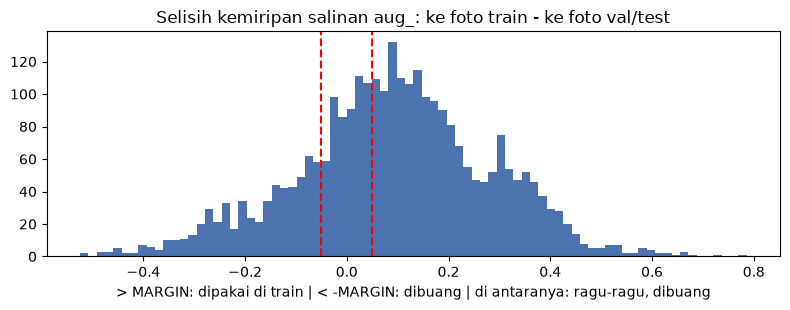

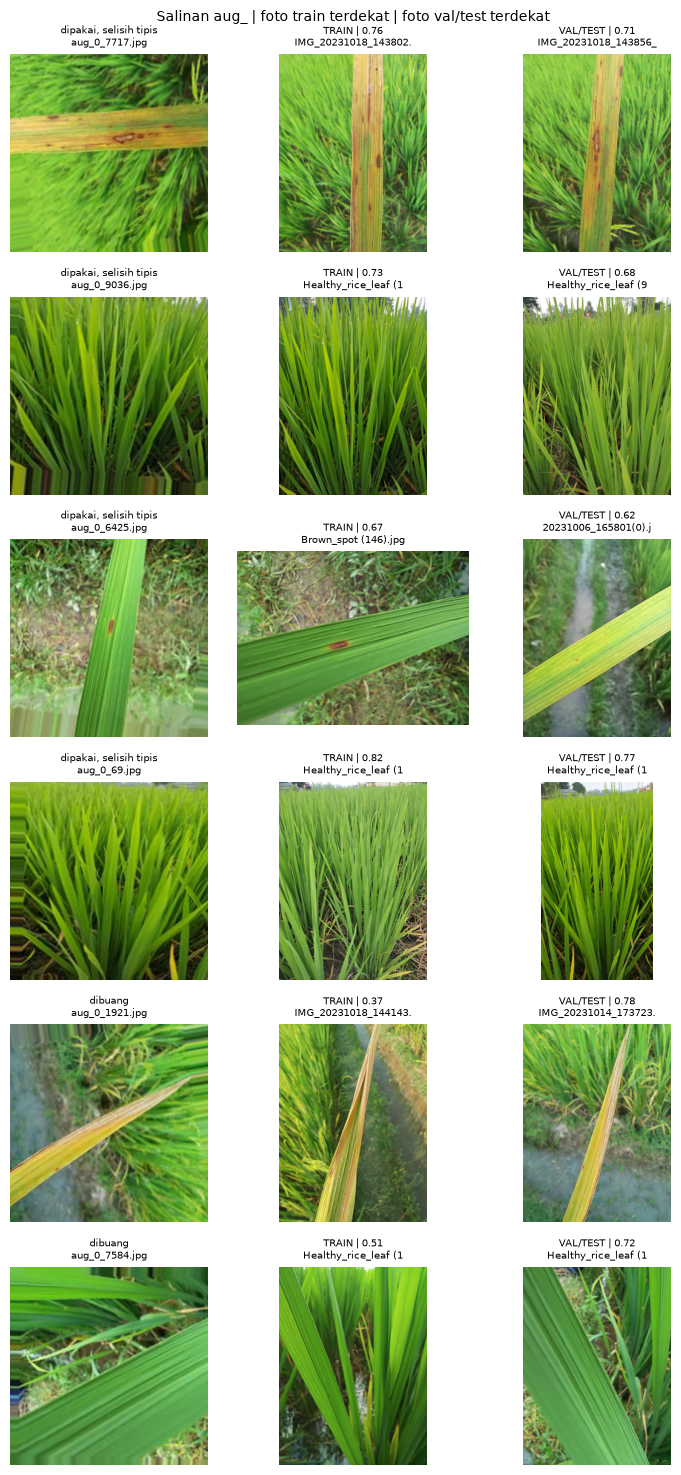

In [14]:
A = df_all[df_all.is_aug & df_all.sim_train.notna()].copy()
A["selisih"] = A.sim_train - A.sim_holdout
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(A.selisih, bins=80, color="#4C72B0")
for v in (-MARGIN, MARGIN):
    ax.axvline(v, color="red", ls="--")
ax.set_title("Selisih kemiripan salinan aug_: ke foto train - ke foto val/test")
ax.set_xlabel("> MARGIN: dipakai di train | < -MARGIN: dibuang | di antaranya: ragu-ragu, dibuang")
plt.tight_layout(); plt.savefig(FIG_DIR / "aug_selisih.png", dpi=150); plt.show()

by_name = df_all.reset_index().set_index("filename")["index"]
used_close = A[(A.status == "dipakai") & (A.alasan == "jelas lebih mirip foto train")].nsmallest(4, "selisih")
dropped = A[A.alasan == "lebih mirip foto validasi/test"].sample(n=min(2, (A.alasan == "lebih mirip foto validasi/test").sum()), random_state=SEED)
rows = [("dipakai, selisih tipis", r) for r in used_close.itertuples()] + [("dibuang", r) for r in dropped.itertuples()]
if rows:
    fig, axes = plt.subplots(len(rows), 3, figsize=(7.5, 2.5 * len(rows)), squeeze=False)
    for r, (t, row) in enumerate(rows):
        items = [(row.Index, f"{t}\n{row.filename[:20]}"),
                 (by_name[row.sumber], f"TRAIN | {row.sim_train:.2f}\n{row.sumber[:20]}"),
                 (by_name[row.sumber_holdout], f"VAL/TEST | {row.sim_holdout:.2f}\n{row.sumber_holdout[:20]}")]
        for c, (k, title) in enumerate(items):
            with Image.open(df_all.path[k]) as im:
                axes[r, c].imshow(du.shrink_pil(im, 200))
            axes[r, c].set_title(title, fontsize=7); axes[r, c].axis("off")
    plt.suptitle("Salinan aug_ | foto train terdekat | foto val/test terdekat", fontsize=10)
    plt.tight_layout(); plt.savefig(FIG_DIR / "aug_pasangan.png", dpi=150); plt.show()

### Tabel 2 laporan: distribusi data per kelas

In [15]:
table2 = pd.crosstab(df.label, df.split).reindex(columns=["train", "val", "test"])
table2["total"] = table2.sum(axis=1)
table2.loc["Total"] = table2.sum()
table2.columns = ["Train", "Validasi", "Uji", "Total"]
pct = (table2.loc["Total", ["Train", "Validasi", "Uji"]] / table2.loc["Total", "Total"] * 100).round(1)
print("Proporsi aktual (%):", pct.to_dict())
table2.to_csv("reports/tabel2_distribusi.csv")
display(table2)
komposisi = pd.crosstab(df.label, [df.split, df.is_aug.map({False: "asli", True: "salinan"})]).reindex(columns=["train", "val", "test"], level=0)
print("Komposisi: validasi dan test hanya berisi foto asli")
komposisi

Proporsi aktual (%): {'Train': 84.0, 'Validasi': 7.9, 'Uji': 8.0}


,Train,Validasi,Uji,Total
label,,,,
Bacterial Leaf Blight,192,14,13,219
Brown Spot,219,23,22,264
Healthy Rice Leaf,342,27,30,399
Leaf Blast,151,17,12,180
Leaf scald,159,11,11,181
Sheath Blight,336,40,46,422
Total,1399,132,134,1665


Komposisi: validasi dan test hanya berisi foto asli


split                 train          val test
is_aug                 asli salinan asli asli
label                                        
Bacterial Leaf Blight    62     130   14   13
Brown Spot              104     115   23   22
Healthy Rice Leaf       130     212   27   30
Leaf Blast               79      72   17   12
Leaf scald               54     105   11   11
Sheath Blight           202     134   40   46

### Mengapa split per kelompok penting?
Pembanding: split acak biasa pada seluruh gambar (termasuk salinan `aug_`).

In [16]:
from sklearn.model_selection import train_test_split
base = df_all[~df_all.group.isin(mixed_ids)]
tr_idx, rest = train_test_split(base.index, test_size=0.30, stratify=base.label, random_state=SEED)
_, te_idx = train_test_split(rest, test_size=0.50, stratify=base.label[rest], random_state=SEED)
bocor = int(base.group[te_idx].isin(set(base.group[tr_idx])).sum())
print(f"Split ACAK         : {bocor} dari {len(te_idx)} gambar test punya 'kembaran' di train ({bocor / len(te_idx):.1%}) - batas bawah")
print(f"Split PER KELOMPOK : 0 dari {int((df.split == 'test').sum())} gambar test punya 'kembaran' di train (0.0%)")

Split ACAK         : 291 dari 574 gambar test punya 'kembaran' di train (50.7%) - batas bawah
Split PER KELOMPOK : 0 dari 134 gambar test punya 'kembaran' di train (0.0%)


## 7. Simpan gambar yang dikecilkan dan `splits.csv`
- Gambar diputar sesuai EXIF dan sisi terpendeknya dikecilkan ke 256 piksel (rasio tetap), disimpan di `data/processed/rice_256/<kelas>/`.
  Fungsi yang sama (`du.shrink_pil`) dipakai aplikasi Streamlit, jadi gambar pengguna diproses persis seperti data latih.
- `data/splits.csv` memakai path relatif terhadap `data/processed/rice_256/`, sehingga tidak bergantung pada nama folder zip.

In [17]:
made = 0
for row in df.itertuples():
    dst = PROCESSED_DIR / row.label / (Path(row.filename).stem + ".jpg")
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        with Image.open(row.path) as im:
            du.shrink_pil(im).save(dst, "JPEG", quality=92)
        made += 1
df["relpath"] = [f"{l}/{Path(f).stem}.jpg" for l, f in zip(df.label, df.filename)]
assert df.relpath.is_unique, "Ada nama file kembar setelah diubah ke .jpg"

keep = {PROCESSED_DIR / r for r in df.relpath}
stale = [p for p in PROCESSED_DIR.rglob("*.jpg") if p not in keep]
for p in stale:
    p.unlink()                                   # hapus gambar yang dibuang (dari run sebelumnya)
print("Gambar lama yang dihapus dari rice_256:", len(stale))
size_mb = sum(p.stat().st_size for p in PROCESSED_DIR.rglob("*.jpg")) / 2**20
print(f"Gambar baru diproses: {made} | ukuran folder rice_256: {size_mb:.1f} MB (dataset asli {df.kb.sum() / 1024:.0f} MB)")

df["jenis"] = np.where(df.is_aug, "salinan_aug", "asli")
df[["relpath", "label", "split", "jenis", "group", "timestamp"]].to_csv(SPLITS_CSV, index=False)
print("Tersimpan:", SPLITS_CSV, "|", df.split.value_counts().reindex(["train", "val", "test"]).to_dict())

Gambar lama yang dihapus dari rice_256: 255
Gambar baru diproses: 236 | ukuran folder rice_256: 40.0 MB (dataset asli 996 MB)
Tersimpan: C:\Users\hp\Downloads\DeepLearning\Deeplearning_rice_disease_prediction\data\splits.csv | {'train': 1399, 'val': 132, 'test': 134}


## 8. Pra-pemrosesan dan augmentasi (dipakai model)
Dari `src/data/data_utils.py`:
- `make_dataset(split)`: resize ke 224x224, piksel rentang 0-255, label integer; augmentasi otomatis hanya untuk train.
- Augmentasi: flip horizontal dan vertikal, rotasi +-15 derajat, zoom +-10%, brightness dan kontras +-20%. Warna (hue) tidak diubah karena warna bercak adalah ciri penyakit.
- Normalisasi di dalam model: CNN baseline memakai `layers.Rescaling(1/255)`, EfficientNet menerima 0-255 langsung.

CLASS_NAMES: ['Bacterial Leaf Blight', 'Brown Spot', 'Healthy Rice Leaf', 'Leaf Blast', 'Leaf scald', 'Sheath Blight']
Batch train: (32, 224, 224, 3) | piksel 0.0 - 255.0 | label [5 5 0 3 1 2 5 5]


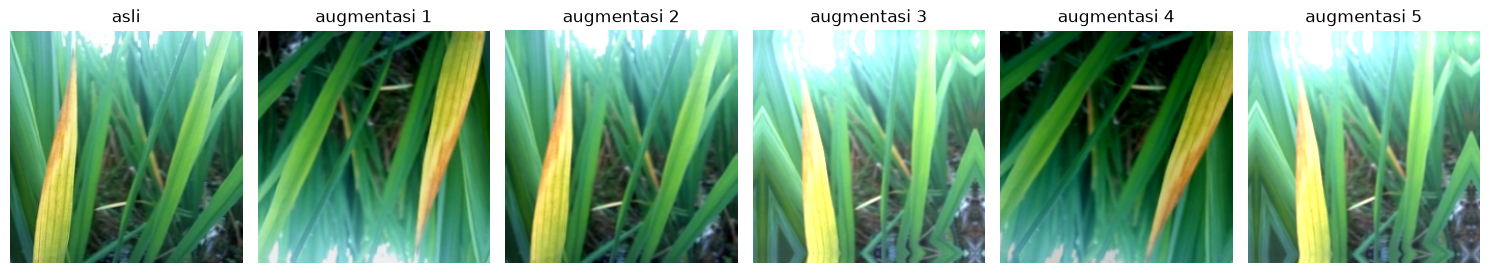

In [18]:
import importlib, tensorflow as tf
du = importlib.reload(du)                       # muat ulang agar CLASS_NAMES terbaca dari splits.csv yang baru
print("CLASS_NAMES:", du.CLASS_NAMES)
train_ds = du.make_dataset("train"); val_ds = du.make_dataset("val"); test_ds = du.make_dataset("test")
xb, yb = next(iter(train_ds))
print("Batch train:", xb.shape, "| piksel", float(tf.reduce_min(xb)), "-", float(tf.reduce_max(xb)), "| label", yb[:8].numpy())

aug = du.build_augmentation()
with Image.open(PROCESSED_DIR / df[df.split == "train"].relpath.iloc[0]) as im:
    img = du.load_for_inference(im)[0]
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(img.astype("uint8")); axes[0].set_title("asli"); axes[0].axis("off")
for k in range(1, 6):
    a = tf.clip_by_value(aug(img[None], training=True)[0], 0, 255).numpy().astype("uint8")
    axes[k].imshow(a); axes[k].set_title(f"augmentasi {k}"); axes[k].axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "contoh_augmentasi.png", dpi=150); plt.show()

## 9. Ringkasan untuk anggota lain
```python
import sys; sys.path.append("..")                     # dari folder notebooks/
from src.data.data_utils import make_dataset, CLASS_NAMES, NUM_CLASSES, SEED
train_ds, val_ds, test_ds = make_dataset("train"), make_dataset("val"), make_dataset("test")
# loss: sparse_categorical_crossentropy | output: Dense(NUM_CLASSES, activation="softmax")
```
- Semua model **wajib** memakai `data/splits.csv` yang sama. Jangan membuat split sendiri.
- Validasi dan test hanya berisi foto asli; salinan `aug_` bawaan dataset hanya ada di train (kolom `jenis`).
- Metrik utama: **macro F1**, karena jumlah foto asli per kelas tidak seimbang dan data test kecil.
- Data test hanya dipakai di evaluasi akhir.
- Gambar di `reports/figures/` dan `reports/tabel2_distribusi.csv` dipakai di laporan bagian 3.1 dan 3.2.

In [19]:
print("Kelas      :", du.CLASS_NAMES)
print("Gambar     :", len(df), f"(dari {len(df_all)}; dibuang {len(df_all) - len(df)})", "| foto asli:", int((~df.is_aug).sum()))
print("Split      :", df.split.value_counts().reindex(["train", "val", "test"]).to_dict())
print("Parameter  : SESSION_GAP_S =", SESSION_GAP_S, "| PHASH_MAX_DIST =", PHASH_MAX_DIST,
      "| MARGIN =", MARGIN, "| ORIG_DUP_MIN =", ORIG_DUP_MIN, "| SEED =", SEED)

Kelas      : ['Bacterial Leaf Blight', 'Brown Spot', 'Healthy Rice Leaf', 'Leaf Blast', 'Leaf scald', 'Sheath Blight']
Gambar     : 1665 (dari 3829; dibuang 2164) | foto asli: 897
Split      : {'train': 1399, 'val': 132, 'test': 134}
Parameter  : SESSION_GAP_S = 5 | PHASH_MAX_DIST = 6 | MARGIN = 0.05 | ORIG_DUP_MIN = 0.9 | SEED = 42


## 10. (Colab) Unduh semua hasil
File di Colab hilang saat sesi ditutup. Sel ini membuat satu zip berisi semua hasil untuk di-commit ke repo.

In [20]:
if "google.colab" in sys.modules:
    import shutil
    bundle = Path("/content/hasil_data_engineer")
    if bundle.exists(): shutil.rmtree(bundle)
    for rel in ["data/splits.csv", "data/processed/rice_256", "reports", "src"]:
        src_p, dst_p = ROOT / rel, bundle / rel
        dst_p.parent.mkdir(parents=True, exist_ok=True)
        (shutil.copytree if src_p.is_dir() else shutil.copy)(src_p, dst_p)
    zip_path = shutil.make_archive("/content/hasil_data_engineer", "zip", bundle)
    print("Ukuran zip:", round(Path(zip_path).stat().st_size / 2**20, 1), "MB")
    from google.colab import files
    files.download(zip_path)
else:
    print("Bukan di Colab: hasil sudah ada di folder repo.")

Bukan di Colab: hasil sudah ada di folder repo.
